<a href="https://colab.research.google.com/github/sumin031130/ESAA/blob/main/ESAA_YB_WEEK12_2_%EC%97%B0%EC%8A%B5%EB%AC%B8%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. 규제 선형 회귀 모델/ 회귀 트리**
- 릿지 회귀모델 및 회귀 트리를 이용하여 전복의 나이를 예측해 보세요.

- 전복의 ‘성별’, ‘키’, ‘지름’, ‘높이’, ‘전체무게’, ‘몸통무게’, ‘내장무게’, ‘껍질무게’를 이용해 ‘껍질의 고리수’를 예측한 뒤, **예측된 ‘껍질의 고리수’에 1.5를 더하면 전복의 나이**가 됩니다.

In [ ]:
# 기본 모듈 불러오기
import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings(action='ignore')

### 1) 데이터 불러오기 및 데이터 선택

In [ ]:
# 데이터 로드
data = pd.read_csv("abalone.csv")

# 성별 M은 Male, F는 Female, I는 Infant 이므로 따로 열 만들기
for label in "MFI":
    data[label] = data["Sex"] == label
data.drop('Sex', axis=1, inplace=True)

# X,y 데이터 선택
y = data.Rings.values
data.drop('Rings', axis=1, inplace=True)

X = data.values.astype(float)

## 2) train/test 분리
: 테스트 셋과 데이터 셋을 7:3 비율로 분리하세요.

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)

print(X_train.shape, X_test.shape)

(2923, 10) (1254, 10)


## 3) 릿지 모델을 이용한 모델링
: 릿지 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

 3-1) 릿지모델 생성, 교차검증, 평가에 필요한 모듈을 불러오세요.

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error

3-2) 릿지 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요. 릿지 모델 생성 시  alpha는 0.3으로 설정합니다. (교차 검증 하지 않습니다.)

In [ ]:
#릿지모델 생성 및 훈련
ridge = Ridge(alpha=0.3)
ridge.fit(X_train, y_train)

#예측값 구하기
pred_rings = ridge.predict(X_test)

#구한 예측값을 활용해 최종적으로 전복의 나이 예측
pred_age = pred_rings + 1.5
true_age = y_test + 1.5

#MSE와 RMSE구하기
mse = mean_squared_error(true_age, pred_age)
rmse = np.sqrt(mse)
print('MSE : {0:.4f}, RMSE : {1:.4f}'.format(mse, rmse))

MSE : 4.7915, RMSE : 2.1890


3-3) 릿지 모델에서 회귀 계수 값을 구해 알 수 있는 점을 작성하시오. (각 컬럼의 정보는 data.colums 참고)

In [ ]:
data.columns

ridge_coef = pd.Series(ridge.coef_, index=data.columns).sort_values(ascending=False)
ridge_coef

,0
Shell weight,9.571586
Diameter,8.730696
Whole weight,8.400012
Height,8.090955
Length,1.203842
M,0.350188
F,0.267680
I,-0.617868
Viscera weight,-8.894914
Shucked weight,-19.258132



- 성별: M(+0.35), F(+0.27)은 양수, I(Infant)는 -0.62로 음수임 → 다른 조건이 같을 때 유생(I)은 성체(M/F)보다 껍질의 고리수(나이)가 적게 예측됨
- 크기 변수 중 껍질무게(+9.57), 지름(+8.73), 전체무게(+8.40), 높이(+8.09)는 양수 → 클수록 고리수(나이)가 많아지는 방향
- 몸통무게(-19.26), 내장무게(-8.89)는 음수 → 다른 변수를 고정했을 때 무거울수록 고리수가 적어지는 방향. 몸통무게의 절댓값이 가장 큼
- 주의: 무게·길이 변수끼리 상관이 0.9 이상으로 매우 높아(다중공선성) 계수 부호를 '그 변수 자체의 효과'로 읽으면 안 됨. 몸통무게·내장무게가 음수인 것은 전체무게·껍질무게와 함께 들어갔을 때 나오는 보정 효과임
- 변수 단위(스케일)가 달라 계수 크기를 그대로 중요도로 비교하기 어려움 (길이·무게 변수는 0~2 범위, 표준화하지 않음)
- 릿지(alpha=0.3)는 계수를 0에 가깝게 줄이는 규제를 하지만 alpha가 작아 계수가 크게 줄지는 않았음

3-3) 교차검증을 이용하여 0, 0.1, 1, 10, 100 중  모델 성능이 가장 좋게 나오는 (rmse가 최소가 되는) alpha를 구하세요.

In [ ]:
# 주어진 alpha
alphas=[0, 0.1, 1, 10, 100]

In [ ]:
rmse_list = []
for alpha in alphas:
  ridge_cv = Ridge(alpha=alpha)

  #cross_val_score를 이용해 5 폴드의 평균 RMSE를 계산
  neg_mse_scores = cross_val_score(ridge_cv, X_train, y_train, scoring='neg_mean_squared_error', cv=5)
  avg_rmse = np.mean(np.sqrt(-1 * neg_mse_scores))
  rmse_list.append(avg_rmse)
  print('alpha {0} 일 때 5 folds 의 평균 RMSE : {1:.4f}'.format(alpha, avg_rmse))

best_alpha = alphas[int(np.argmin(rmse_list))]
print('RMSE가 최소가 되는 alpha :', best_alpha)

alpha 0 일 때 5 folds 의 평균 RMSE : 2.2377
alpha 0.1 일 때 5 folds 의 평균 RMSE : 2.2275
alpha 1 일 때 5 folds 의 평균 RMSE : 2.2160
alpha 10 일 때 5 folds 의 평균 RMSE : 2.3578
alpha 100 일 때 5 folds 의 평균 RMSE : 2.6235
RMSE가 최소가 되는 alpha : 1


## 4) XGBRegressor을 이용한 모델링
: XGBRegressor 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

4-1) XGBRegressor 훈련, 평가에 필요한 모듈을 불러오세요.

In [ ]:
from xgboost import XGBRegressor

4-2) XGBregressor 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요.

In [ ]:
#모델 생성 및 훈련
xgb_reg = XGBRegressor(random_state=123)
xgb_reg.fit(X_train, y_train)

#예측값 구하기
xgb_pred_rings = xgb_reg.predict(X_test)

#구한 예측값을 활용해 최종적으로 전복의 나이 예측
xgb_pred_age = xgb_pred_rings + 1.5

#MSE와 RMSE 구하기
xgb_mse = mean_squared_error(true_age, xgb_pred_age)
xgb_rmse = np.sqrt(xgb_mse)
print('MSE : {0:.4f}, RMSE : {1:.4f}'.format(xgb_mse, xgb_rmse))

MSE : 5.5804, RMSE : 2.3623


4-3) 생성한 모델의 피처 중요도를 시각화해보세요.

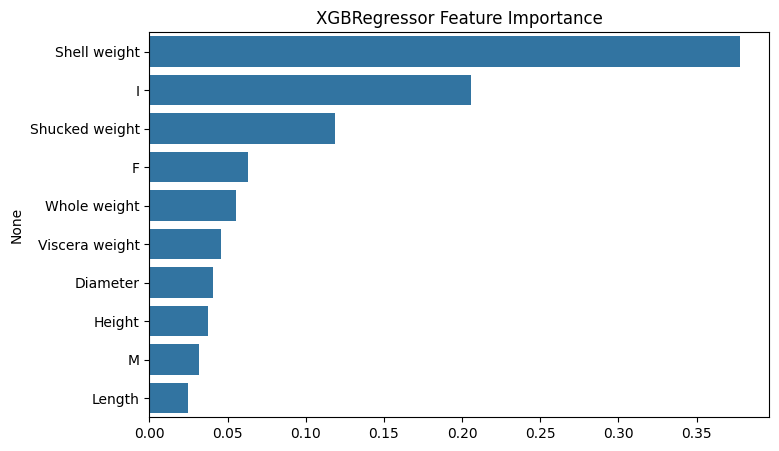

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

imp = pd.Series(xgb_reg.feature_importances_, index=data.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index)
plt.title('XGBRegressor Feature Importance')
plt.show()

# **2. 로지스틱 회귀분석**
load_wine() 함수를 이용하여 와인 데이터를 다항분류하는 로지스틱 회귀모델을 생성하세요.

In [ ]:
# 필요한 모듈 불러오기
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

## 1) 데이터 불러오기 및 변수 선택

In [ ]:
wine = load_wine()

wine_x = wine.data # x변수
wine_y = wine.target # y변수

## 2) train/test 셋 분리

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(wine_x, wine_y, test_size=0.3, random_state=123)

x_train.shape
y_train.shape

(124,)

## 3) 로지스틱 회귀모델을 이용한 모델링

3-1) 로지스틱 회귀모델을 생성하여 훈련하세요.

In [ ]:
lr = LogisticRegression(max_iter=5000)
lr.fit(x_train, y_train)

LogisticRegression(max_iter=5000)

3-2) 회귀 모델의 기울기와 절편을 구하세요.

In [ ]:
#기울기
lr.coef_

array([[ 5.40119857e-01,  5.55141609e-01,  6.20476859e-01,
        -2.58233732e-01, -1.45090139e-04,  2.55690914e-01,
         7.52039277e-01,  8.78394493e-02,  1.63790241e-01,
         1.96653394e-01,  1.22113689e-02,  5.19222294e-01,
         8.77112451e-03],
       [-6.96442843e-01, -9.22500438e-01, -7.03121269e-01,
         1.51118933e-01, -4.31236620e-02,  3.12399569e-01,
         1.59485268e-01,  1.17931800e-02,  3.72214630e-01,
        -9.37234424e-01,  2.86879368e-01,  1.35291197e-01,
        -7.77953721e-03],
       [ 1.56322986e-01,  3.67358828e-01,  8.26444092e-02,
         1.07114799e-01,  4.32687521e-02, -5.68090483e-01,
        -9.11524545e-01, -9.96326293e-02, -5.36004871e-01,
         7.40581030e-01, -2.99090737e-01, -6.54513491e-01,
        -9.91587312e-04]])

In [ ]:
#절편
lr.intercept_

array([-15.57767711,  22.74821606,  -7.17053895])

3-3) 모델의 정확도를 구하세요.

In [ ]:
#모델의 예측값 구하기
pred = lr.predict(x_test)

#모델의 정확도 구하기
acc = metrics.accuracy_score(y_test, pred)
print('정확도 : {0:.4f}'.format(acc))

정확도 : 0.9630
